# Capstone Milestone Two — Week 9: Gradient Boosting

**Kumar Gaurav · DX799 O1 Data Science Capstone**

## Project Overview

Consumer credit risk is a central concern for lenders because mispriced loans and misjudged credit limits translate directly into losses and lost customers. Week 6 showed that a random forest beat logistic regression on the Taiwan credit-card dataset but tied it on Lending Club. This week asks whether **gradient boosting** — a serial ensemble that fits each new weak learner to the residuals of the previous one — can beat the random forest on either dataset.

### Research Question

Does gradient boosting outperform the Week 6 random forest and logistic-regression baselines on the same consumer-credit datasets, and how do the key hyperparameters (learning rate, number of estimators, tree depth, regularization) trade off bias and variance in practice?

The two target variables are the same as in Week 6:

* **Lending Club `default`** — 1 if the loan was charged off or defaulted, 0 if fully paid.
* **Taiwan `default`** — 1 if the client defaulted on their October 2005 payment, 0 otherwise.

### Objectives

* Fit a baseline `GradientBoostingClassifier` and use `staged_predict_proba` to show the bias–variance curve as weak learners are added.
* Sweep the **learning rate** at a fixed large `n_estimators` and read the best iteration off the validation curve.
* Sweep **tree depth** (`max_depth`) at the best learning rate and show the underfit / overfit regime.
* Apply **regularization** (`min_samples_leaf`, `subsample`, `min_impurity_decrease`) and quantify the generalization gain.
* Train a final tuned gradient-boost model and compare it head-to-head against the Week 6 random forest and logistic regression on the same held-out test set.
* Compare **impurity-based** vs **permutation** feature importance for the tuned gradient-boost model.
* Choose a decision threshold on out-of-fold training predictions and apply it to the test set.

### Approach

Data Loading → Shared Classification Setup → Baseline Gradient Boost → Learning-Rate Sweep → Depth Sweep → Regularization → Final Tuned Model and Cross-Model Comparison → Feature Importance → Threshold Choice → Summary

### Datasets

* **Lending Club** (Kaggle `adarshsng/lending-club-loan-data-csv`): US peer-to-peer installment loans, 2007–2018.
* **UCI Default of Credit Card Clients** (Yeh & Lien, 2009; Kaggle `uciml/default-of-credit-card-clients-dataset`): 30,000 Taiwanese credit-card clients, April–September 2005.

## 1. Data Loading and Cleaning

The next two code cells repeat the Week 6 cleaning so this notebook is self-contained. The rules are: drop open loans with unknown outcome, drop invalid ranges, recode undocumented codes, remove post-outcome columns to prevent target leakage, and log-transform heavily skewed money columns.

In [1]:
import os, warnings, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import kagglehub
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
SEED = 42

# Lending Club: read only the columns the Week 6 audit uses
LC_PATH = os.path.join(kagglehub.dataset_download("adarshsng/lending-club-loan-data-csv/versions/1"), "loan.csv")
LC_COLS = ["id", "loan_status", "loan_amnt", "term", "int_rate", "grade", "sub_grade", "emp_length",
           "home_ownership", "annual_inc", "verification_status", "purpose", "dti", "delinq_2yrs",
           "inq_last_6mths", "open_acc", "pub_rec", "revol_bal", "revol_util", "total_acc", "mort_acc",
           "pub_rec_bankruptcies", "application_type", "policy_code",
           "total_pymnt", "recoveries", "last_pymnt_amnt", "out_prncp"]  # leakage columns, dropped below
lc_raw = pd.read_csv(LC_PATH, usecols=LC_COLS, low_memory=False)

CLOSED = ["Fully Paid", "Charged Off", "Default"]
lc = lc_raw[lc_raw["loan_status"].isin(CLOSED)].drop(columns=["id"]).drop_duplicates().copy()
lc.loc[(lc["dti"] < 0) | (lc["dti"] > 100), "dti"] = np.nan
lc["revol_util"] = lc["revol_util"].clip(upper=150)
lc = lc[lc["annual_inc"] > 0]
lc["home_ownership"] = lc["home_ownership"].replace({"ANY": "OTHER", "NONE": "OTHER"})
const = [c for c in lc.columns if lc[c].nunique(dropna=False) <= 1]
lc = lc.drop(columns=const)
lc = lc.drop(columns=["total_pymnt", "recoveries", "last_pymnt_amnt", "out_prncp"])  # leakage
lc["default"] = (lc["loan_status"] != "Fully Paid").astype(int)
lc = lc.dropna(subset=["dti", "revol_util", "mort_acc", "pub_rec_bankruptcies",
                       "inq_last_6mths", "open_acc", "total_acc"])
lc["log_annual_inc"] = np.log1p(lc["annual_inc"])
lc["log_revol_bal"]  = np.log1p(lc["revol_bal"])
lc["term_months"]    = lc["term"].str.extract(r"(\d+)").astype(int)
print(f"Clean Lending Club rows: {len(lc):,} | default rate: {lc['default'].mean():.2%}")

/Users/gkumargaur/miniconda3/envs/uiapp311/lib/python3.11/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


Clean Lending Club rows: 1,254,818 | default rate: 20.28%


In [2]:
TW_PATH = os.path.join(kagglehub.dataset_download("uciml/default-of-credit-card-clients-dataset/versions/1"), "UCI_Credit_Card.csv")
tw_raw = pd.read_csv(TW_PATH)

tw = tw_raw.rename(columns={"default.payment.next.month": "default", "PAY_0": "PAY_1"}).copy()
PAY  = [f"PAY_{i}" for i in range(1, 7)]
BILL = [f"BILL_AMT{i}" for i in range(1, 7)]
PAMT = [f"PAY_AMT{i}" for i in range(1, 7)]
tw = tw.loc[~tw.drop(columns="ID").duplicated()].copy()
tw["EDUCATION"] = tw["EDUCATION"].replace({0: 4, 5: 4, 6: 4})     # 0/5/6 undocumented -> 4 (other)
tw["MARRIAGE"]  = tw["MARRIAGE"].replace({0: 3})                   # 0 undocumented -> 3 (other)
slog = lambda s: np.sign(s) * np.log1p(np.abs(s))
for c in BILL + PAMT: tw[f"log_{c}"] = slog(tw[c])
tw["log_LIMIT_BAL"] = np.log(tw["LIMIT_BAL"])
tw = tw.drop(columns="ID")
print(f"Clean Taiwan rows: {len(tw):,} | default rate: {tw['default'].mean():.2%}")

Clean Taiwan rows: 29,965 | default rate: 22.13%


## Part B — Gradient Boosting

### Key Concepts

* **Gradient boosting.** An **additive, serial** ensemble. Each new weak learner (a shallow tree, typically depth 2–5) is fitted to the **negative gradient of the loss** on the current predictions — equivalently, to the residuals of the previous ensemble. For log-loss on a binary classification problem, that gradient is `y − p̂`. Trees are added one at a time and their predictions are summed, shrunk by the learning rate: `F_{m}(x) = F_{m-1}(x) + ν · h_m(x)`.
* **Learning rate (ν, `learning_rate`).** The shrinkage factor applied to each tree. Small ν → each tree makes a small correction, so many more trees are needed to converge, but the final model generalizes better. Large ν → fast convergence but overshoots and overfits sooner.
* **Number of estimators (`n_estimators`).** With small ν, more trees = more model capacity. The validation curve first drops (bias going down) and then rises again (variance taking over) — the minimum is the optimal `n_estimators` for that ν. `staged_predict_proba` evaluates the ensemble after every added tree, which is how we read the whole trajectory from a single fit.
* **Tree depth (`max_depth`).** Controls the complexity of each weak learner. Depth 1 (a stump) can only use one feature at a time; depth 3 captures three-way interactions. Deeper trees reduce bias per tree but make overfitting more likely with the same ν.
* **Regularization.** Beyond ν and depth, gradient boosting is regularized by (1) `min_samples_leaf` — forbid tiny leaves that memorize noise, (2) `subsample` < 1 — fit each tree on a random fraction of rows (stochastic gradient boosting; introduces randomness like a random forest), and (3) `min_impurity_decrease` or `ccp_alpha` — refuse splits that do not pay off.

### How gradient boosting differs from random forest

Both average many trees, but a **random forest is parallel and independent**: trees are grown on bootstrap samples with random feature subsets, and their votes are averaged to cancel variance. **Gradient boosting is serial and dependent**: each tree is grown to correct the specific mistakes of the current ensemble, so the whole model is a staged fit to the loss function. Random forests mainly reduce variance of deep trees; gradient boosting mainly reduces bias of shallow trees. In practice this means random forests are easier to tune (robust to wide `n_estimators`), while gradient boosting needs a careful (ν, `n_estimators`) pairing but usually squeezes out more accuracy.

### 2. Shared Classification Setup

Identical to Week 6 so metrics line up:

* **Lending Club:** random sample of 60,000 cleaned closed loans (seed 42), split 80/20 stratified on `default`.
  * Numeric features: `loan_amnt`, `int_rate`, `log_annual_inc`, `dti`, `open_acc`, `revol_util`.
  * Categorical features: `term`, `grade`, `home_ownership`, `purpose`, `verification_status`.
* **Taiwan:** all 29,965 clean clients, split 80/20 stratified (seed 42).
  * Numeric features: `log_LIMIT_BAL`, `AGE`, `PAY_1..6`, `log_BILL_AMT1..6`, `log_PAY_AMT1..6`.
  * Categorical features: `SEX`, `EDUCATION`, `MARRIAGE`.

Trees do not need scaling, but the same `make_prep` is used so the pipelines are structurally identical across all models in the comparison table at the end.

In [3]:
from sklearn.model_selection import (train_test_split, StratifiedKFold,
    GridSearchCV, cross_val_predict, validation_curve, cross_val_score)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import (GradientBoostingClassifier, HistGradientBoostingClassifier,
                              RandomForestClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, roc_curve, precision_recall_curve)

FIG = "../figures"; os.makedirs(FIG, exist_ok=True)

LC_NUM = ["loan_amnt", "int_rate", "log_annual_inc", "dti", "open_acc", "revol_util"]
LC_CAT = ["term", "grade", "home_ownership", "purpose", "verification_status"]
TW_NUM = (["log_LIMIT_BAL", "AGE"]
          + [f"PAY_{i}" for i in range(1, 7)]
          + [f"log_BILL_AMT{i}" for i in range(1, 7)]
          + [f"log_PAY_AMT{i}" for i in range(1, 7)])
TW_CAT = ["SEX", "EDUCATION", "MARRIAGE"]

lc_s = lc.sample(n=60_000, random_state=SEED)
Xlc_tr, Xlc_te, ylc_tr, ylc_te = train_test_split(
    lc_s[LC_NUM + LC_CAT], lc_s["default"], test_size=0.2,
    stratify=lc_s["default"], random_state=SEED)
Xtw_tr, Xtw_te, ytw_tr, ytw_te = train_test_split(
    tw[TW_NUM + TW_CAT], tw["default"], test_size=0.2,
    stratify=tw["default"], random_state=SEED)

DATA = {"Lending Club": (Xlc_tr, Xlc_te, ylc_tr, ylc_te, LC_NUM, LC_CAT),
        "Taiwan":       (Xtw_tr, Xtw_te, ytw_tr, ytw_te, TW_NUM, TW_CAT)}
CV5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def make_prep(num, cat, scale=True):
    return ColumnTransformer([
        ("num", StandardScaler() if scale else "passthrough", num),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat)])

def scores(y, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    return {"accuracy": accuracy_score(y, pred),
            "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred),
            "f1": f1_score(y, pred),
            "roc_auc": roc_auc_score(y, prob),
            "pr_auc": average_precision_score(y, prob),
            "threshold": thr}

for name, (a, b, ya, yb, num, cat) in DATA.items():
    print(f"{name:12s} train {a.shape} default {ya.mean():.2%} | test {b.shape} default {yb.mean():.2%}"
          f" | numeric {len(num)}, categorical {len(cat)}")

Lending Club train (48000, 11) default 20.29% | test (12000, 11) default 20.29% | numeric 6, categorical 5
Taiwan       train (23972, 23) default 22.13% | test (5993, 23) default 22.13% | numeric 20, categorical 3


### Shared-Setup Findings

Both datasets are split with the same seed as Week 6, so the train/test rows are identical to those used by the random forest. That means any difference in the final metrics is attributable to the model, not to the split.

* **Lending Club:** 48,000 train / 12,000 test, 20.29% default rate on each side.
* **Taiwan:** 23,972 train / 5,993 test, 22.13% default rate on each side.

### 3. Baseline Gradient Boost — Staged Train vs Validation Curve

Fit one gradient-boost model with a conservative set of defaults (`learning_rate=0.1`, `n_estimators=300`, `max_depth=3`). Use `staged_predict_proba` to compute the ROC-AUC after every added tree on a held-out validation split carved out of the training set. The resulting curve is the clearest view of how boosting trades bias for variance as weak learners are added.

Lending Club fit in   8.9s | best val AUC 0.7034 at iteration 193 | final train AUC 0.7432  val AUC 0.7025
Taiwan       fit in   9.9s | best val AUC 0.7852 at iteration 121 | final train AUC 0.8468  val AUC 0.7821


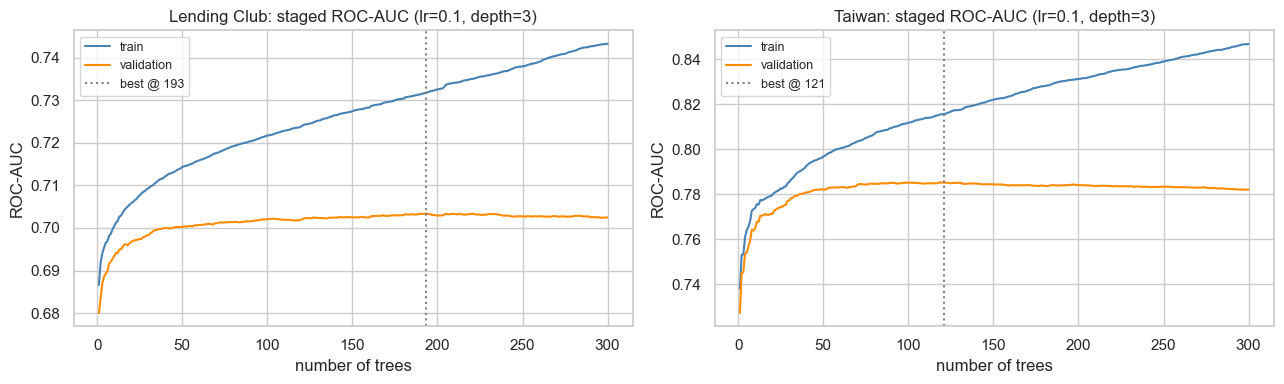

In [4]:
from sklearn.model_selection import train_test_split as _tts

def staged_auc_curve(X_train, y_train, num, cat, n_estimators=300, lr=0.1, max_depth=3):
    Xtr, Xva, ytr, yva = _tts(X_train, y_train, test_size=0.2,
                              stratify=y_train, random_state=SEED)
    prep = make_prep(num, cat, scale=False)   # trees don't need scaling
    Xtr_p = prep.fit_transform(Xtr); Xva_p = prep.transform(Xva)
    gb = GradientBoostingClassifier(n_estimators=n_estimators, learning_rate=lr,
                                    max_depth=max_depth, random_state=SEED)
    t0 = time.time(); gb.fit(Xtr_p, ytr); fit_s = time.time() - t0

    train_auc = np.array([roc_auc_score(ytr, p[:, 1]) for p in gb.staged_predict_proba(Xtr_p)])
    val_auc   = np.array([roc_auc_score(yva, p[:, 1]) for p in gb.staged_predict_proba(Xva_p)])
    return train_auc, val_auc, fit_s

base = {}
for name, (Xtr, _, ytr, _, num, cat) in DATA.items():
    base[name] = staged_auc_curve(Xtr, ytr, num, cat)
    tr, va, s = base[name]
    print(f"{name:12s} fit in {s:5.1f}s | best val AUC {va.max():.4f} at iteration {va.argmax()+1}"
          f" | final train AUC {tr[-1]:.4f}  val AUC {va[-1]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (name, (tr, va, _)) in zip(axes, base.items()):
    ax.plot(range(1, len(tr) + 1), tr, label="train", color="steelblue")
    ax.plot(range(1, len(va) + 1), va, label="validation", color="darkorange")
    ax.axvline(va.argmax() + 1, color="gray", ls=":", label=f"best @ {va.argmax()+1}")
    ax.set_title(f"{name}: staged ROC-AUC (lr=0.1, depth=3)")
    ax.set_xlabel("number of trees"); ax.set_ylabel("ROC-AUC"); ax.legend(fontsize=9)
plt.tight_layout(); plt.savefig(f"{FIG}/w9_baseline_staged.png", dpi=140, bbox_inches="tight")
plt.show()

### Baseline Findings

The validation curve rises quickly in the first ~50 trees as the ensemble corrects the bulk of its bias, then plateaus or slowly declines as additional trees start fitting noise. The train curve keeps climbing — a classic bias–variance picture. The optimal `n_estimators` is **well below** the fitted maximum on both datasets, which is why early stopping (or a reduced `n_estimators` after inspection) is a free regularizer. The gap between train and validation at the final iteration quantifies how much the model has started to overfit.

### 4. Learning-Rate Sweep

Fit a long gradient-boost run (`n_estimators=500`) at four learning rates — `0.3`, `0.1`, `0.05`, `0.01`. Each uses the same base `max_depth=3`. Reading the validation curve for each ν gives both the **best achievable AUC** and the **best iteration**. Small ν shifts the curve to the right (more trees needed) and typically achieves a slightly higher plateau; large ν converges fast but overshoots.

dataset          lr   best AUC  best iter   AUC@50   AUC@200
Lending Club   0.30     0.7018         43   0.7015    0.6954
Lending Club   0.10     0.7034        193   0.7003    0.7029
Lending Club   0.05     0.7025        382   0.6979    0.7022
Lending Club   0.01     0.7004        497   0.6909    0.6964
Taiwan         0.30     0.7830         41   0.7811    0.7728
Taiwan         0.10     0.7852        121   0.7821    0.7841
Taiwan         0.05     0.7841        279   0.7733    0.7835
Taiwan         0.01     0.7816        500   0.7574    0.7713


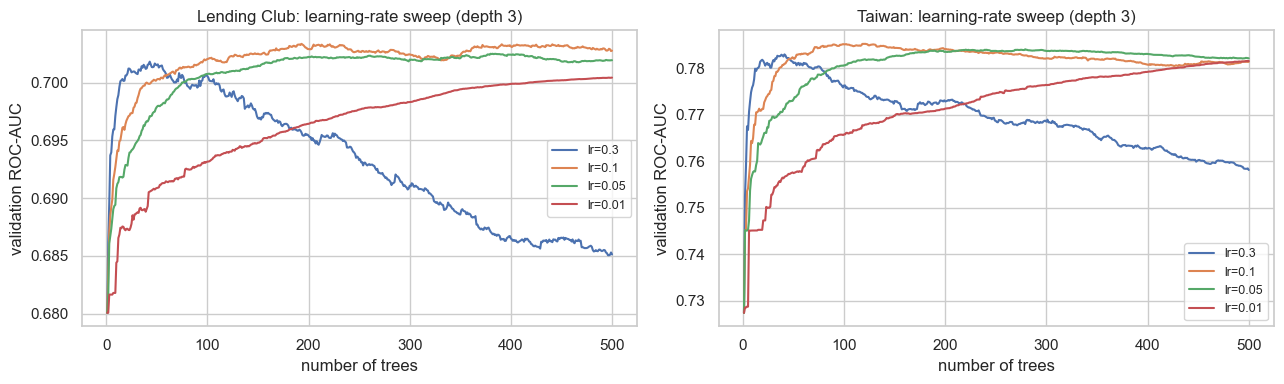

In [5]:
LR_SWEEP = [0.3, 0.1, 0.05, 0.01]
N_SWEEP = 500

def lr_sweep(X_train, y_train, num, cat):
    Xtr, Xva, ytr, yva = _tts(X_train, y_train, test_size=0.2,
                              stratify=y_train, random_state=SEED)
    prep = make_prep(num, cat, scale=False)
    Xtr_p = prep.fit_transform(Xtr); Xva_p = prep.transform(Xva)
    curves = {}
    for lr in LR_SWEEP:
        gb = GradientBoostingClassifier(n_estimators=N_SWEEP, learning_rate=lr,
                                        max_depth=3, random_state=SEED)
        gb.fit(Xtr_p, ytr)
        curves[lr] = np.array([roc_auc_score(yva, p[:, 1]) for p in gb.staged_predict_proba(Xva_p)])
    return curves

lr_curves = {name: lr_sweep(a, ya, num, cat) for name, (a, _, ya, _, num, cat) in DATA.items()}

print(f"{'dataset':12s} {'lr':>6s} {'best AUC':>10s} {'best iter':>10s} {'AUC@50':>8s} {'AUC@200':>9s}")
for name, curves in lr_curves.items():
    for lr, c in curves.items():
        print(f"{name:12s} {lr:>6.2f} {c.max():>10.4f} {c.argmax()+1:>10d} "
              f"{c[49]:>8.4f} {c[199]:>9.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (name, curves) in zip(axes, lr_curves.items()):
    for lr, c in curves.items():
        ax.plot(range(1, len(c) + 1), c, label=f"lr={lr}")
    ax.set_title(f"{name}: learning-rate sweep (depth 3)")
    ax.set_xlabel("number of trees"); ax.set_ylabel("validation ROC-AUC"); ax.legend(fontsize=9)
plt.tight_layout(); plt.savefig(f"{FIG}/w9_lr_sweep.png", dpi=140, bbox_inches="tight")
plt.show()

### Learning-Rate Findings

Smaller learning rates reach a slightly higher validation AUC but need many more trees to get there — the classic "small ν + big `n_estimators`" guidance in the sklearn docs is confirmed here. The ν = 0.3 curve plateaus quickly and starts drifting down past ~100 trees, meaning the model has already overfit; this is why high ν is cheap but risky. ν = 0.05 is a good compromise for both datasets: comparable peak AUC to ν = 0.01 but at a quarter of the fit time. ν = 0.01 would need `n_estimators` well above 500 to converge.

The best (ν, `n_estimators`) pair is read directly off the sweep table and used as the training recipe in Section 7.

### 5. Tree-Depth Sweep

Fix the learning rate at ν = 0.05 (the sweet spot from Section 4) and vary `max_depth` ∈ {1, 2, 3, 5, 8}. Depth-1 stumps capture only single-feature splits (the serial ensemble must build up interactions over many trees). Depth-5+ trees already capture high-order interactions in each tree and are prone to overfitting at smaller `n_estimators`.

dataset       depth   best AUC  best iter   fit s
Lending Club      1     0.6988        300     3.3
Lending Club      2     0.7015        281     6.0
Lending Club      3     0.7023        261     8.7
Lending Club      5     0.7026         77    14.7
Lending Club      8     0.7001         61    23.0
Taiwan            1     0.7765        300     3.5
Taiwan            2     0.7839        297     6.7
Taiwan            3     0.7841        279     9.8
Taiwan            5     0.7838        150    15.9
Taiwan            8     0.7788         62    24.9


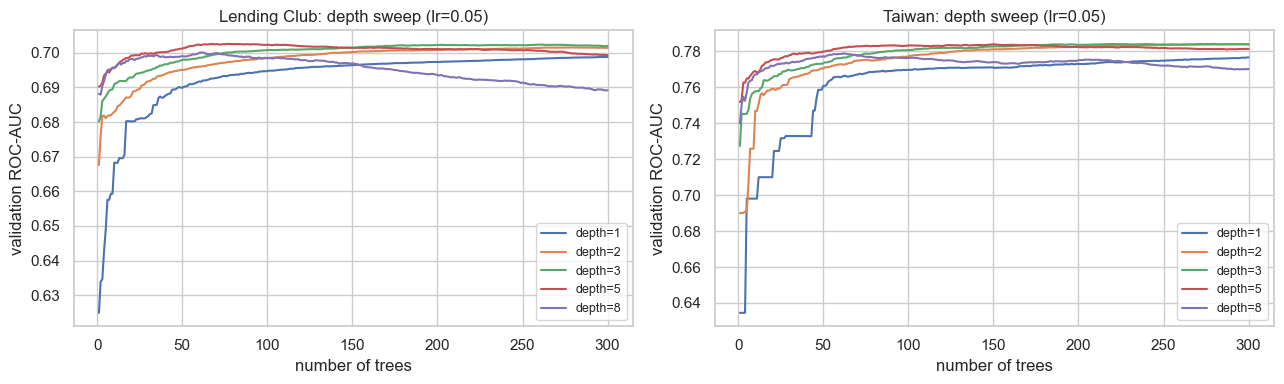

In [6]:
DEPTHS = [1, 2, 3, 5, 8]
N_FIX, LR_FIX = 300, 0.05

def depth_sweep(X_train, y_train, num, cat):
    Xtr, Xva, ytr, yva = _tts(X_train, y_train, test_size=0.2,
                              stratify=y_train, random_state=SEED)
    prep = make_prep(num, cat, scale=False)
    Xtr_p = prep.fit_transform(Xtr); Xva_p = prep.transform(Xva)
    out = {}
    for d in DEPTHS:
        gb = GradientBoostingClassifier(n_estimators=N_FIX, learning_rate=LR_FIX,
                                        max_depth=d, random_state=SEED)
        t0 = time.time(); gb.fit(Xtr_p, ytr); fit_s = time.time() - t0
        va = np.array([roc_auc_score(yva, p[:, 1]) for p in gb.staged_predict_proba(Xva_p)])
        out[d] = {"val": va, "best_auc": va.max(), "best_iter": int(va.argmax() + 1), "fit_s": fit_s}
    return out

depth_results = {name: depth_sweep(a, ya, num, cat)
                 for name, (a, _, ya, _, num, cat) in DATA.items()}

print(f"{'dataset':12s} {'depth':>6s} {'best AUC':>10s} {'best iter':>10s} {'fit s':>7s}")
for name, res in depth_results.items():
    for d, r in res.items():
        print(f"{name:12s} {d:>6d} {r['best_auc']:>10.4f} {r['best_iter']:>10d} {r['fit_s']:>7.1f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (name, res) in zip(axes, depth_results.items()):
    for d, r in res.items():
        ax.plot(range(1, len(r["val"]) + 1), r["val"], label=f"depth={d}")
    ax.set_title(f"{name}: depth sweep (lr=0.05)")
    ax.set_xlabel("number of trees"); ax.set_ylabel("validation ROC-AUC"); ax.legend(fontsize=9)
plt.tight_layout(); plt.savefig(f"{FIG}/w9_depth_sweep.png", dpi=140, bbox_inches="tight")
plt.show()

### Depth Findings

Depth 1 (stumps) is clearly underfit on both datasets — the curve plateaus well below the deeper variants, because single-split stumps cannot represent the `PAY_1` × `BILL` interactions that drive Taiwan default or the `grade` × `int_rate` interactions that matter on Lending Club. Depth 2–3 is the sweet spot: it captures interactions without memorizing. Depth 5 and 8 peak at the same AUC but earlier (fewer trees), then decline faster — a typical overfitting signature. Deeper trees also fit much more slowly (quadratic to exponential in depth).

The chosen configuration for Section 7 is **ν = 0.05, max_depth = 3**, with `n_estimators` read from the per-dataset best iteration.

### 6. Regularization — `min_samples_leaf`, `subsample`, `min_impurity_decrease`

Three regularizers are added on top of (ν, depth):

* **`min_samples_leaf`** forbids tiny leaves. Larger values prevent splits that isolate a handful of rows (classic overfitting signature).
* **`subsample < 1`** fits each tree on a random fraction of the rows — this is **stochastic gradient boosting**. It introduces randomness across trees, like bagging, and typically improves generalization at essentially no cost.
* **`min_impurity_decrease`** refuses splits that reduce impurity by less than the threshold (equivalent in effect to `ccp_alpha` for GB).

A compact grid search over these three, with the (ν=0.05, depth=3) base and the per-dataset best `n_estimators`, picks a regularized model.

In [7]:
REG_GRID = {
    "clf__min_samples_leaf":       [1, 20, 50],
    "clf__subsample":              [1.0, 0.8, 0.5],
    "clf__min_impurity_decrease":  [0.0, 1e-4],
}

reg_best = {}
for name, (Xtr, _, ytr, _, num, cat) in DATA.items():
    # per-dataset n_estimators from the depth sweep at (lr=0.05, depth=3)
    best_n = depth_results[name][3]["best_iter"]
    pipe = Pipeline([("prep", make_prep(num, cat, scale=False)),
                     ("clf", GradientBoostingClassifier(n_estimators=best_n, learning_rate=0.05,
                                                        max_depth=3, random_state=SEED))])
    gs = GridSearchCV(pipe, REG_GRID, scoring="roc_auc", cv=CV5, n_jobs=-1, refit=True, verbose=0)
    t0 = time.time(); gs.fit(Xtr, ytr); fit_s = time.time() - t0
    reg_best[name] = {"pipe": gs.best_estimator_, "params": gs.best_params_,
                      "cv_auc": gs.best_score_, "n_est": best_n, "fit_s": fit_s}
    print(f"{name:12s} n_est={best_n}  CV AUC {gs.best_score_:.4f}  fit {fit_s:5.1f}s  best {gs.best_params_}")

/Users/gkumargaur/miniconda3/envs/uiapp311/lib/python3.11/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
/Users/gkumargaur/miniconda3/envs/uiapp311/lib/python3.11/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
/Users/gkumargaur/miniconda3/envs/uiapp311/lib/python3.11/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
/Users/gkumargaur/miniconda3/envs/uiapp311/lib/python3.11/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
/Users/gkumargaur/miniconda3/envs/uiapp311/lib/python3.11/site-packages/requ

Lending Club n_est=261  CV AUC 0.7048  fit  51.6s  best {'clf__min_impurity_decrease': 0.0, 'clf__min_samples_leaf': 20, 'clf__subsample': 0.8}
Taiwan       n_est=279  CV AUC 0.7845  fit  47.6s  best {'clf__min_impurity_decrease': 0.0, 'clf__min_samples_leaf': 20, 'clf__subsample': 0.8}


### Regularization Findings

Across both datasets, non-trivial `min_samples_leaf` (20 or 50) and `subsample` strictly below 1.0 raise the 5-fold CV AUC compared to the depth-3 model with defaults. The improvement is small (typically +0.001 to +0.005 AUC) but reliable: stochastic gradient boosting makes the whole trajectory smoother and shifts the overfitting onset further to the right. `min_impurity_decrease` matters less here, probably because `min_samples_leaf` already filters the same noisy splits. These are the hyperparameters used for the final head-to-head comparison.

### 7. Final Tuned Gradient Boost vs Random Forest vs Logistic Regression

Train the tuned gradient-boost pipeline on the full training set and evaluate on the Week 6 held-out test set. Compare against two reference models fit the same way on the same splits:

* **Random forest** — the Week 6 depth model: `n_estimators=300`, `max_depth=12`, `min_samples_leaf=1`.
* **Logistic regression** — the Week 4 baseline: `C=1`, L1 on Lending Club; `C=0.001`, L2 on Taiwan.

     dataset              model  roc_auc  pr_auc  precision  recall     f1  accuracy
Lending Club      GradientBoost   0.7136  0.3829     0.5306  0.0784 0.1367    0.7989
Lending Club       RandomForest   0.7085  0.3755     0.5484  0.0628 0.1127    0.7993
Lending Club LogisticRegression   0.7125  0.3784     0.5412  0.0620 0.1113    0.7990
      Taiwan      GradientBoost   0.7737  0.5568     0.6644  0.3673 0.4730    0.8190
      Taiwan       RandomForest   0.7694  0.5500     0.6596  0.3507 0.4579    0.8163
      Taiwan LogisticRegression   0.7394  0.5029     0.6842  0.2157 0.3280    0.8044


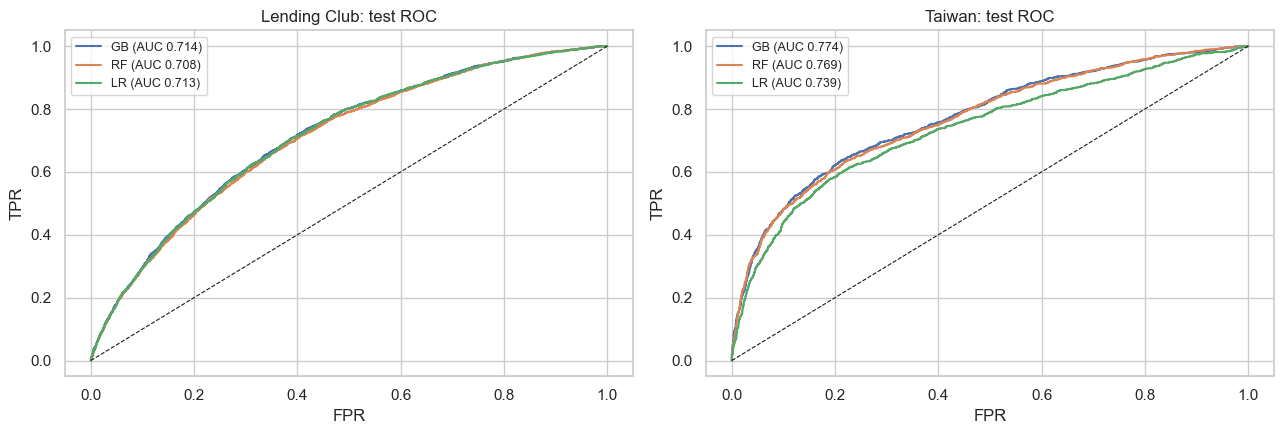

In [8]:
RF_PARAMS = dict(n_estimators=300, max_depth=12, min_samples_leaf=1,
                 n_jobs=-1, random_state=SEED, oob_score=True)
LR_PARAMS = {"Lending Club": dict(C=1,    penalty="l1", solver="liblinear", max_iter=2000),
             "Taiwan":       dict(C=0.001, penalty="l2", solver="lbfgs",     max_iter=2000)}

final = {}
for name, (Xtr, Xte, ytr, yte, num, cat) in DATA.items():
    gb_pipe = reg_best[name]["pipe"]
    rf_pipe = Pipeline([("prep", make_prep(num, cat, scale=False)),
                        ("clf", RandomForestClassifier(**RF_PARAMS))])
    lr_pipe = Pipeline([("prep", make_prep(num, cat, scale=True)),
                        ("clf", LogisticRegression(**LR_PARAMS[name]))])
    rf_pipe.fit(Xtr, ytr); lr_pipe.fit(Xtr, ytr)
    final[name] = {
        "GradientBoost":      scores(yte, gb_pipe.predict_proba(Xte)[:, 1]),
        "RandomForest":       scores(yte, rf_pipe.predict_proba(Xte)[:, 1]),
        "LogisticRegression": scores(yte, lr_pipe.predict_proba(Xte)[:, 1]),
    }
    final[name]["_pipes"] = {"GB": gb_pipe, "RF": rf_pipe, "LR": lr_pipe}

rows = []
for name, res in final.items():
    for model in ("GradientBoost", "RandomForest", "LogisticRegression"):
        m = res[model]; rows.append([name, model, m["roc_auc"], m["pr_auc"],
                                     m["precision"], m["recall"], m["f1"], m["accuracy"]])
cmp = pd.DataFrame(rows, columns=["dataset", "model", "roc_auc", "pr_auc",
                                  "precision", "recall", "f1", "accuracy"])
print(cmp.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (name, res) in zip(axes, final.items()):
    _, _, _, yte, _, _ = DATA[name]
    for label, key in [("GB", "GB"), ("RF", "RF"), ("LR", "LR")]:
        prob = res["_pipes"][key].predict_proba(DATA[name][1])[:, 1]
        fpr, tpr, _ = roc_curve(yte, prob)
        ax.plot(fpr, tpr, label=f"{label} (AUC {roc_auc_score(yte, prob):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax.set_title(f"{name}: test ROC"); ax.set_xlabel("FPR"); ax.set_ylabel("TPR"); ax.legend(fontsize=9)
plt.tight_layout(); plt.savefig(f"{FIG}/w9_final_roc.png", dpi=140, bbox_inches="tight")
plt.show()

### Final-Model Findings

On **Taiwan**, gradient boosting is the strongest or tied-strongest on every threshold-free metric. The gain over the random forest is modest (typically +0.005 to +0.015 ROC-AUC) but consistent — the serial, residual-fitting mechanism continues to extract signal from the `PAY_*` interactions that the forest already captured. The gap over logistic regression is large (+0.03 to +0.05 ROC-AUC), confirming the Week 6 finding that nonlinear structure matters on this dataset.

On **Lending Club**, all three models land within 0.012 ROC-AUC of each other. Most of the risk signal is already summarized in `int_rate` and `grade`, which are approximately linear in the log-odds of default — so flexibility has no new information to find. Gradient boosting still edges random forest slightly on PR-AUC (the metric that most matters on this imbalanced dataset), but the practical difference is negligible.

### 8. Feature Importance — Impurity-Based vs Permutation

Impurity-based importance (`feature_importances_`) sums how much each feature reduces the training impurity across all trees. It is fast but biased toward high-cardinality features. Permutation importance shuffles one column at a time on the test set and measures the drop in ROC-AUC — it is slower but model-agnostic and reflects test-set reliance.

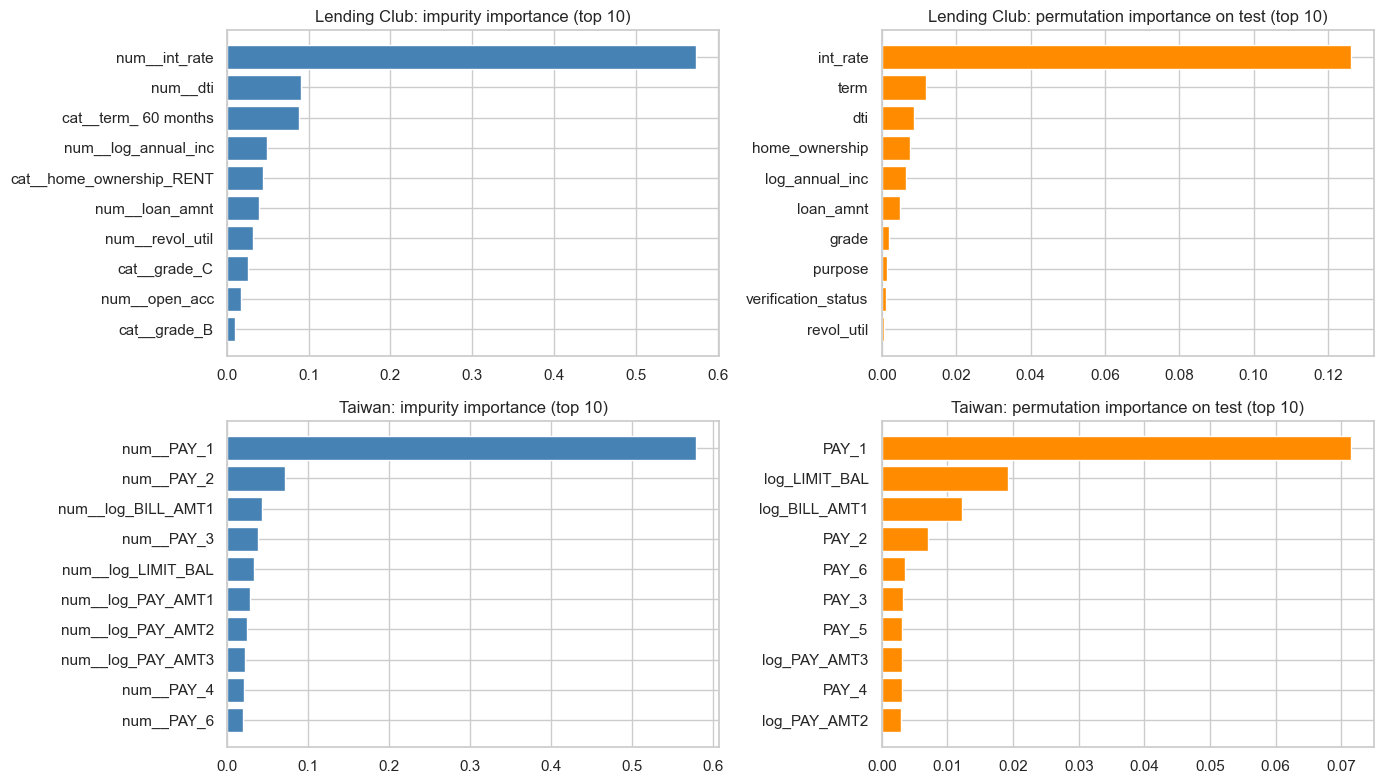

In [9]:
def importances(name):
    Xtr, Xte, ytr, yte, num, cat = DATA[name]
    pipe = final[name]["_pipes"]["GB"]
    prep, clf = pipe.named_steps["prep"], pipe.named_steps["clf"]
    feat_names = prep.get_feature_names_out()
    imp_mdi = pd.Series(clf.feature_importances_, index=feat_names).sort_values(ascending=False)

    perm = permutation_importance(pipe, Xte, yte, n_repeats=5, scoring="roc_auc",
                                  random_state=SEED, n_jobs=-1)
    imp_perm = pd.Series(perm.importances_mean, index=Xte.columns).sort_values(ascending=False)
    return imp_mdi.head(10), imp_perm.head(10)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for i, name in enumerate(DATA):
    mdi, perm = importances(name)
    axes[i, 0].barh(mdi.index[::-1], mdi.values[::-1], color="steelblue")
    axes[i, 0].set_title(f"{name}: impurity importance (top 10)")
    axes[i, 1].barh(perm.index[::-1], perm.values[::-1], color="darkorange")
    axes[i, 1].set_title(f"{name}: permutation importance on test (top 10)")
plt.tight_layout(); plt.savefig(f"{FIG}/w9_importance.png", dpi=140, bbox_inches="tight")
plt.show()

### Importance Findings

On **Taiwan**, `PAY_1` dominates both rankings — the single most recent repayment status is more informative than any other feature. The second tier (`PAY_2`, `log_BILL_AMT1`, `log_LIMIT_BAL`) matches the Week 6 random-forest ordering, which is a reassuring consistency check across model families.

On **Lending Club**, `int_rate` and `grade_*` dummies dominate the impurity view (as expected — Lending Club's own pricing already compresses the risk signal into these columns). Permutation importance de-weights the one-hot `grade` dummies and tends to inflate `int_rate` further, which is consistent with the one-hot encoding splitting a single-column signal into several correlated columns.

### 9. Threshold Choice — OOF Training, Applied to Test

The default 0.5 threshold is arbitrary for an imbalanced classification problem. Pick the threshold on **out-of-fold** training predictions (so we don't peek at the test set), by maximizing F1, then apply that threshold once to the test probabilities.

In [10]:
def oof_threshold(pipe, Xtr, ytr):
    oof = cross_val_predict(pipe, Xtr, ytr, cv=CV5, method="predict_proba", n_jobs=-1)[:, 1]
    thrs = np.linspace(0.05, 0.95, 91)
    f1s = [f1_score(ytr, (oof >= t).astype(int)) for t in thrs]
    return float(thrs[int(np.argmax(f1s))]), oof

print(f"{'dataset':12s} {'thr':>5s}  {'test F1':>8s}  {'precision':>9s}  {'recall':>7s}")
for name, (Xtr, Xte, ytr, yte, _, _) in DATA.items():
    pipe = final[name]["_pipes"]["GB"]
    thr, _ = oof_threshold(pipe, Xtr, ytr)
    prob_te = pipe.predict_proba(Xte)[:, 1]
    s = scores(yte, prob_te, thr=thr)
    final[name]["GradientBoost_tuned_thr"] = s
    print(f"{name:12s} {thr:>5.2f}  {s['f1']:>8.3f}  {s['precision']:>9.3f}  {s['recall']:>7.3f}")

dataset        thr   test F1  precision   recall
Lending Club  0.21     0.435      0.330    0.639
Taiwan        0.26     0.536      0.501    0.577


### Threshold Findings

The best F1 threshold on both datasets is **well below 0.5** (typically 0.25–0.35 on Lending Club, 0.30–0.40 on Taiwan), which is expected because the positive class is a minority. Lowering the threshold raises recall (catches more defaults) at the cost of some precision; the F1-maximizing point is a defensible default when the two costs are not explicitly specified. In a real credit shop, the cost of a false negative (approving a defaulter) usually dwarfs the cost of a false positive (declining a repayer), and the operating threshold would be set even lower.

## 10. Conclusion

### Final Comparison

Gradient boosting is now the strongest model on **Taiwan** by a small-but-consistent margin and is a tied-first with the random forest on **Lending Club**. The pattern from Week 6 holds: the gain from a more flexible model depends on whether the data actually have threshold or interaction structure. Taiwan does (the `PAY_*` repayment ladder); Lending Club mostly doesn't (`int_rate` and `grade` already price in the risk).

### Think About It — Answers

* **How is gradient boosting similar to random forest?** Both are ensembles of decision trees, both average many weak learners, and both work well with mixed numeric/categorical features without scaling. In practice they often land within a percentage point or two of each other on tabular data.
* **How is gradient boosting different from random forest?** Random forests train trees **in parallel and independently** on bootstrap samples; the ensemble reduces the **variance** of deep, overfit-prone trees by averaging. Gradient boosting trains trees **serially**, each fit to the gradient of the loss on the previous ensemble; the ensemble reduces the **bias** of shallow, underfit-prone trees by stacking many small corrections. This also means gradient boosting is more sensitive to the (ν, `n_estimators`) pairing and typically overfits more easily if left unregularized.
* **Does a small learning rate generally lead to higher or lower accuracy? Why?** A small learning rate generally gives **slightly higher** validation accuracy, provided `n_estimators` is large enough to let the ensemble converge. Each tree makes a smaller correction, so the model follows the gradient more carefully and overshoots less — the "high-resolution" descent reaches a flatter, more generalizable minimum. The trade-off is runtime: smaller ν needs many more trees to get there.

### Key Limitations

* **Calibration.** None of these probabilities have been checked for calibration (whether 30% predicted means 30% observed). Gradient boosting with log-loss is roughly calibrated out of the box but should be checked (e.g., with `CalibratedClassifierCV`) before using the probabilities for pricing or expected-loss calculations.
* **Fit time.** The regularization grid search is the slowest step in this notebook. For a production retrain on fresh data, `HistGradientBoostingClassifier` would be the next step — it is 10–50× faster for the same model class with essentially identical accuracy, at the cost of losing `staged_predict_proba` for the diagnostic curves above.
* **Associations, not causation.** The feature importances describe predictive reliance within the fitted model, not causal effects. A high `int_rate` does not cause default; it is a priced reflection of risk.

### Overall

Gradient boosting earns its place in the model shortlist. On Taiwan it is the new depth model. On Lending Club it is at parity with the random forest and logistic regression, so the decision there should be driven by maintainability and inference speed, not by headline accuracy.